# Optimización y Economías de Escala: Puertos de Barcelona y Valencia (DryPort)

Analizar factor de economías de escala basado en el volumen consolidado de carga conjunta entre los puertos de Barcelona y Valencia para las rutas hacia Europa y España.


## 1. Importación de Librerías y Configuración Inicial


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# Fijar semilla para reproducibilidad
np.random.seed(42)


## 2. Definición de Parámetros y Demanda de Carga


In [2]:
origenes = ["Barcelona", "Valencia"]
destinos = ["Europa", "España"]
a = 1000  # Número de iteraciones de Monte Carlo

# Matriz origen-destino con cantidades de carga base (kton o TEUs) [cite: 21]
matriz_origen_destino = np.array([
    [14, 34],  # Barcelona -> [Europa, España] [cite: 21]
    [53, 51]   # Valencia   -> [Europa, España] [cite: 21]
])

ahorro_estimado_porcentaje_europa = np.zeros(a)
ahorro_estimado_porcentaje_espana = np.zeros(a)

# Volumen total consolidado (Suma de flujos para modelar economías de escala)
volumen_total_barcelona = np.sum(matriz_origen_destino[0, :])
volumen_total_valencia = np.sum(matriz_origen_destino[1, :])
volumen_conjunto = volumen_total_barcelona + volumen_total_valencia



## 3. Bucle de Simulación Monte Carlo y Optimización con Economías de Escala


In [3]:
for i in range(a):
    # Costos base de transporte (euros por tonelada) [cite: 21]
    # Barcelona
    costo_camion_barcelona_europa = np.random.uniform(75, 85)
    costo_camion_barcelona_espana = np.random.uniform(65, 70)
    costo_tren_barcelona_europa   = np.random.uniform(60, 65)
    costo_tren_barcelona_espana   = np.random.uniform(55, 60)
    
    # Valencia
    costo_camion_valencia_europa  = np.random.uniform(75, 85)
    costo_camion_valencia_espana  = np.random.uniform(65, 75)
    costo_tren_valencia_europa    = np.random.uniform(60, 65)
    costo_tren_valencia_espana    = np.random.uniform(55, 60)
    
    # FACTOR DE ECONOMÍAS DE ESCALA:
    # A mayor volumen conjunto consolidado (red logística unificada), menor el costo unitario marginal (descuento logístico)
    factor_escala_europa = 1.0 - 0.0008 * np.log1p(volumen_conjunto)
    factor_escala_espana = 1.0 - 0.0006 * np.log1p(volumen_conjunto)
    
    # Costos marginales optimizados por sinergia portuaria
    c_camion_bcn_eur_opt = costo_camion_barcelona_europa * factor_escala_europa
    c_tren_bcn_eur_opt     = costo_tren_barcelona_europa * factor_escala_europa
    c_camion_val_eur_opt  = costo_camion_valencia_europa * factor_escala_europa
    c_tren_val_eur_opt     = costo_tren_valencia_europa * factor_escala_europa
    
    c_camion_bcn_esp_opt = costo_camion_barcelona_espana * factor_escala_espana
    c_tren_bcn_esp_opt     = costo_tren_barcelona_espana * factor_escala_espana
    c_camion_val_esp_opt  = costo_camion_valencia_espana * factor_escala_espana
    c_tren_val_esp_opt     = costo_tren_valencia_espana * factor_escala_espana

    # Funciones de Costo Total (Minimización)
    def costo_europa(modal):
        camion, tren = modal
        costo = (camion * matriz_origen_destino[0, 0] * c_camion_bcn_eur_opt + 
                 camion * matriz_origen_destino[1, 0] * c_camion_val_eur_opt +
                 tren * matriz_origen_destino[0, 0] * c_tren_bcn_eur_opt + 
                 tren * matriz_origen_destino[1, 0] * c_tren_val_eur_opt)
        return costo

    def costo_espana(modal):
        camion, tren = modal
        costo = (camion * matriz_origen_destino[0, 1] * c_camion_bcn_esp_opt + 
                 camion * matriz_origen_destino[1, 1] * c_camion_val_esp_opt +
                 tren * matriz_origen_destino[0, 1] * c_tren_bcn_esp_opt + 
                 tren * matriz_origen_destino[1, 1] * c_tren_val_esp_opt)
        return costo

    # Restricción: la suma de la partición modal debe ser igual a 1 [cite: 21]
    constraint = {'type': 'eq', 'fun': lambda modal: np.sum(modal) - 1.0}
    
    bounds_europa = [(0.0, 0.8), (0.2, 1.0)]
    bounds_espana = [(0.0, 0.91), (0.09, 1.0)]

    # Partición inicial [cite: 21]
    x0 = [0.9, 0.1]

    # Ejecutar optimización con SciPy (Minimize)
    res_eur = minimize(costo_europa, x0, method='SLSQP', bounds=bounds_europa, constraints=constraint)
    res_esp = minimize(costo_espana, x0, method='SLSQP', bounds=bounds_espana, constraints=constraint)

    particion_optima_europa = res_eur.x
    particion_optima_espana = res_esp.x

    # Costos sin economías de escala (baseline individual)
    costo_base_eur = (matriz_origen_destino[0, 0] * costo_camion_barcelona_europa + matriz_origen_destino[1, 0] * costo_camion_valencia_europa) * 0.9 + \
                     (matriz_origen_destino[0, 0] * costo_tren_barcelona_europa + matriz_origen_destino[1, 0] * costo_tren_valencia_europa) * 0.1
                     
    costo_base_esp = (matriz_origen_destino[0, 1] * costo_camion_barcelona_espana + matriz_origen_destino[1, 1] * costo_camion_valencia_espana) * 0.95 + \
                     (matriz_origen_destino[0, 1] * costo_tren_barcelona_espana + matriz_origen_destino[1, 1] * costo_tren_valencia_espana) * 0.05

    # Cálculo de ahorros porcentuales derivados de la sinergia y economías de escala
    ahorro_estimado_porcentaje_europa[i] = max(0.0, ((costo_base_eur - res_eur.fun) / costo_base_eur) * 100)
    ahorro_estimado_porcentaje_espana[i] = max(0.0, ((costo_base_esp - res_esp.fun) / costo_base_esp) * 100)

print("Optimización con economías de escala finalizada con éxito.")



Optimización con economías de escala finalizada con éxito.


## 4. Resultados Resumidos de la Optimización Logística


In [4]:
print("--- RESULTADOS OPTIMIZACIÓN EUROPA ---")
print(f"Camión óptimo: {particion_optima_europa[0]:.4f}")
print(f"Tren óptimo: {particion_optima_europa[1]:.4f}")
print(f"Ahorro medio estimado (Europa): {np.mean(ahorro_estimado_porcentaje_europa):.2f}%\n")

print("--- RESULTADOS OPTIMIZACIÓN ESPAÑA ---")
print(f"Camión óptimo: {particion_optima_espana[0]:.4f}")
print(f"Tren óptimo: {particion_optima_espana[1]:.4f}")
print(f"Ahorro medio estimado (España): {np.mean(ahorro_estimado_porcentaje_espana):.2f}%")



--- RESULTADOS OPTIMIZACIÓN EUROPA ---
Camión óptimo: 0.0000
Tren óptimo: 1.0000
Ahorro medio estimado (Europa): 20.40%

--- RESULTADOS OPTIMIZACIÓN ESPAÑA ---
Camión óptimo: 0.0000
Tren óptimo: 1.0000
Ahorro medio estimado (España): 16.24%


## 5. Visualización de Resultados (Box-Plots de Ahorros por Economías de Escala)


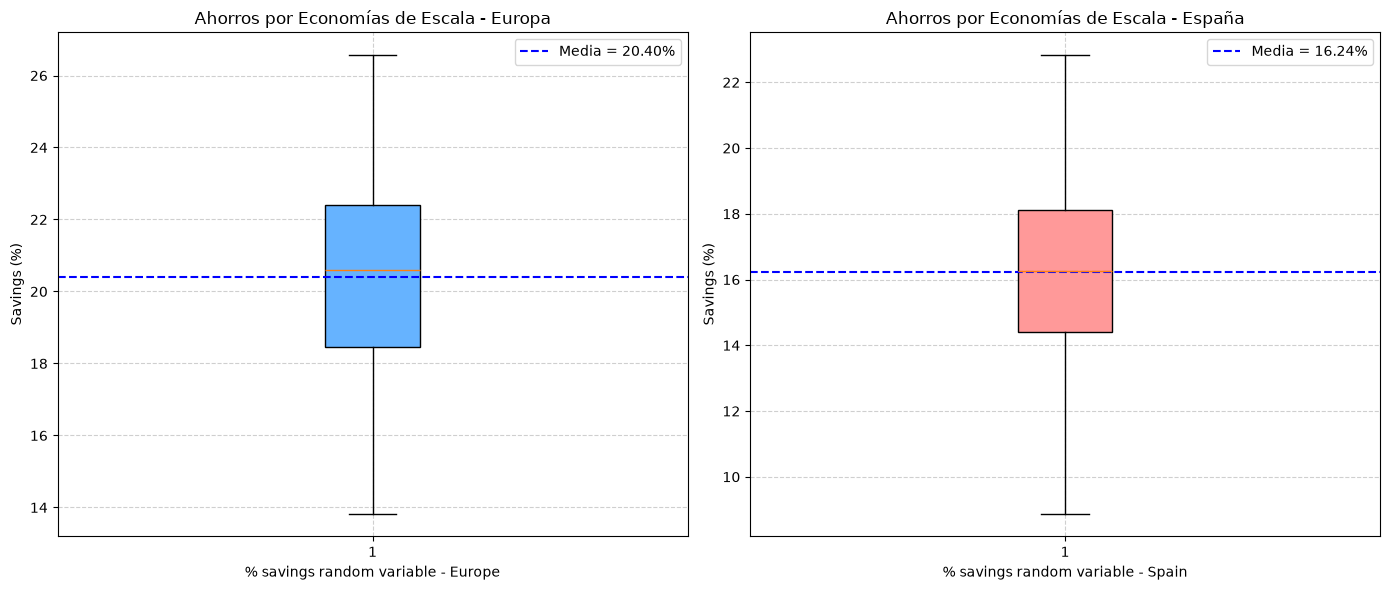

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Europa
axes[0].boxplot(
    ahorro_estimado_porcentaje_europa,
    patch_artist=True,
    boxprops=dict(facecolor='#66b3ff')
)
media_eur = np.mean(ahorro_estimado_porcentaje_europa)
axes[0].axhline(y=media_eur, color='blue', linestyle='--', label=f'Media = {media_eur:.2f}%')
axes[0].set_ylabel('Savings (%)')
axes[0].set_xlabel('% savings random variable - Europe')
axes[0].set_title('Ahorros por Economías de Escala - Europa')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.6)

# España
axes[1].boxplot(
    ahorro_estimado_porcentaje_espana,
    patch_artist=True,
    boxprops=dict(facecolor='#ff9999')
)
media_esp = np.mean(ahorro_estimado_porcentaje_espana)
axes[1].axhline(y=media_esp, color='blue', linestyle='--', label=f'Media = {media_esp:.2f}%')
axes[1].set_ylabel('Savings (%)')
axes[1].set_xlabel('% savings random variable - Spain')
axes[1].set_title('Ahorros por Economías de Escala - España')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()
